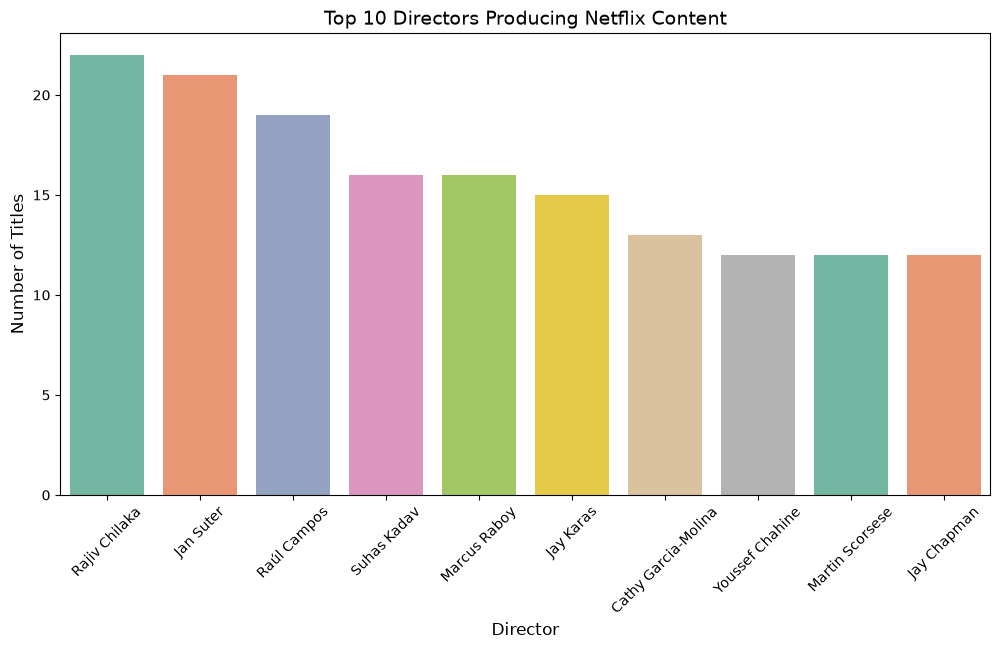

In [33]:
directors_series = df['director'].dropna().str.split(',').explode().str.strip()
top_directors = directors_series.value_counts().head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_directors.index,
    y=top_directors.values,
    hue=top_directors.index,
    palette='Set2',
    legend=False,
)

plt.title('Top 10 Directors Producing Netflix Content', fontsize=14)
plt.xlabel('Director', fontsize=12)
plt.ylabel('Number of Titles', fontsize=12)
plt.xticks(rotation=45) 

plt.show()

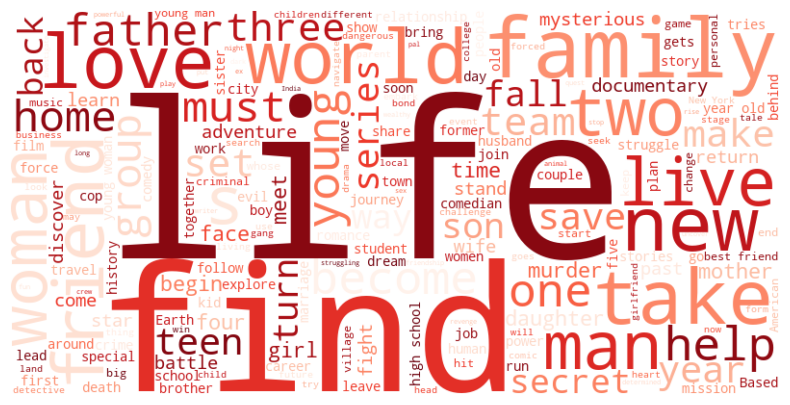

In [34]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# clean up missing values and join all descriptions into one giant string
text = " ".join(df['description'].dropna().astype(str))

# create and generate the word cloud object
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(text)

# display it using Matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off') # Hides the x and y axis numbers
plt.show()

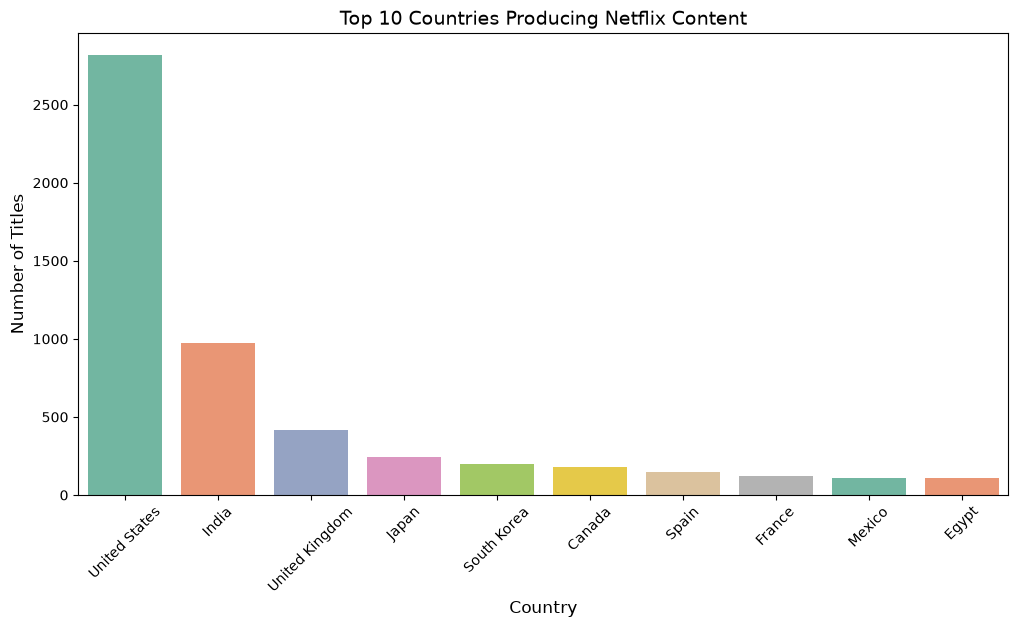

In [35]:
top_countries = df['country'].value_counts().head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_countries.index,
    y=top_countries.values,
    hue=top_countries.index,
    palette='Set2',
    legend=False,
)

plt.title('Top 10 Countries Producing Netflix Content', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Titles', fontsize=12)
plt.xticks(rotation=45) 

plt.show()

release_year
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
2020     953
2021     592
Name: count, dtype: int64


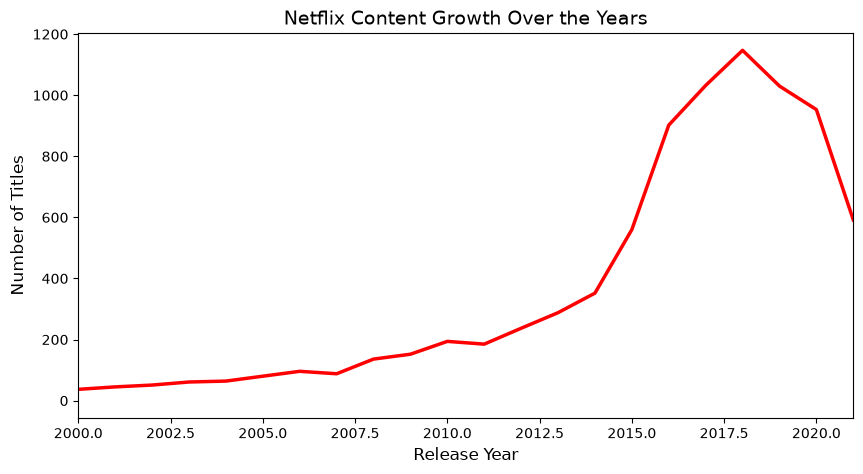

In [36]:
yearly_counts = df['release_year'].value_counts().sort_index()
print(yearly_counts.tail(10))

plt.figure(figsize=(10, 5))
sns.lineplot(x=yearly_counts.index, y=yearly_counts.values, linewidth=2.5, color='red')
plt.title('Netflix Content Growth Over the Years', fontsize=14)
plt.xlabel('Release Year', fontsize=12)
plt.ylabel('Number of Titles', fontsize=12)
plt.xlim(2000, 2021)

plt.show()

Dataset Shape: (8807, 12)

First 3 rows:
  show_id     type                 title         director  \
0      s1    Movie  Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show         Blood & Water              NaN   
2      s3  TV Show             Ganglands  Julien Leclercq   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021          2021  TV-MA   1 Season   

                                           listed_in  \
0                                      Documentaries   
1    International TV Shows, TV Dramas, TV Mysteries   
2  Crime TV Shows, International

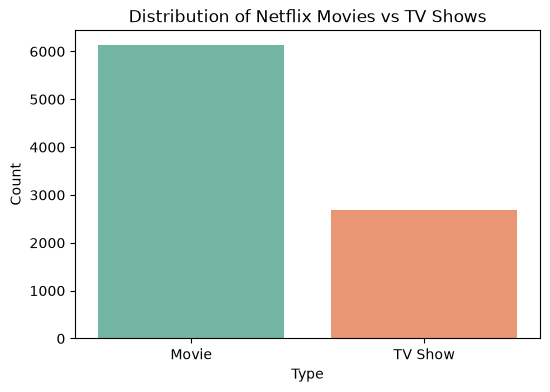

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_csv('netflix_titles.csv')

print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:")
print(df.head(3))

# missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# fill missing ratings with a placeholder or drop rows
df['rating'] = df['rating'].fillna('TV-MA')

# count of movies vs TV shows
print("\nContent Types breakdown:")
print(df['type'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x='type', data=df, hue='type', palette='Set2', legend=False)
plt.title('Distribution of Netflix Movies vs TV Shows')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()